In [3]:
"""
Black-Scholes Option Pricing & Greeks Engine
============================================
Library-style module. Safe to import in Colab/Jupyter.
"""

from __future__ import annotations
from dataclasses import dataclass
from math import exp, isfinite, log, sqrt
from typing import Literal

import numpy as np
from scipy.stats import norm


OptionType = Literal["call", "put"]


@dataclass(frozen=True)
class OptionInputs:
    spot: float
    strike: float
    time_to_maturity: float
    volatility: float
    risk_free_rate: float
    dividend_yield: float = 0.0

    def validate(self) -> None:
        values = (self.spot, self.strike, self.time_to_maturity,
                  self.volatility, self.risk_free_rate, self.dividend_yield)
        if not all(isfinite(v) for v in values):
            raise ValueError("All model inputs must be finite numbers.")
        if self.spot <= 0:
            raise ValueError("Spot price must be > 0.")
        if self.strike <= 0:
            raise ValueError("Strike price must be > 0.")
        if self.time_to_maturity <= 0:
            raise ValueError("Time to maturity must be > 0.")
        if self.volatility <= 0:
            raise ValueError("Volatility must be > 0.")


def _d1_d2(params: OptionInputs) -> tuple[float, float]:
    params.validate()
    s, k, t = params.spot, params.strike, params.time_to_maturity
    sigma, r, q = params.volatility, params.risk_free_rate, params.dividend_yield
    d1 = (log(s / k) + (r - q + 0.5 * sigma ** 2) * t) / (sigma * sqrt(t))
    d2 = d1 - sigma * sqrt(t)
    return d1, d2


def black_scholes_price(params: OptionInputs, option_type: OptionType) -> float:
    d1, d2 = _d1_d2(params)
    s, k, t = params.spot, params.strike, params.time_to_maturity
    r, q = params.risk_free_rate, params.dividend_yield
    ds = s * exp(-q * t)
    dk = k * exp(-r * t)

    if option_type == "call":
        return ds * norm.cdf(d1) - dk * norm.cdf(d2)
    if option_type == "put":
        return dk * norm.cdf(-d2) - ds * norm.cdf(-d1)
    raise ValueError("option_type must be 'call' or 'put'.")


def option_greeks(params: OptionInputs, option_type: OptionType) -> dict[str, float]:
    d1, d2 = _d1_d2(params)
    s, k, t = params.spot, params.strike, params.time_to_maturity
    sigma, r, q = params.volatility, params.risk_free_rate, params.dividend_yield

    dq, dr = exp(-q * t), exp(-r * t)
    pdf_d1 = norm.pdf(d1)

    gamma = dq * pdf_d1 / (s * sigma * sqrt(t))
    vega = s * dq * pdf_d1 * sqrt(t)

    if option_type == "call":
        delta = dq * norm.cdf(d1)
        theta = (-(s * dq * pdf_d1 * sigma) / (2 * sqrt(t))
                 - r * k * dr * norm.cdf(d2)
                 + q * s * dq * norm.cdf(d1))
        rho = k * t * dr * norm.cdf(d2)
    elif option_type == "put":
        delta = dq * (norm.cdf(d1) - 1)
        theta = (-(s * dq * pdf_d1 * sigma) / (2 * sqrt(t))
                 + r * k * dr * norm.cdf(-d2)
                 - q * s * dq * norm.cdf(-d1))
        rho = -k * t * dr * norm.cdf(-d2)
    else:
        raise ValueError("option_type must be 'call' or 'put'.")

    return {
        "Delta": delta,
        "Gamma": gamma,
        "Vega": vega,
        "Vega per 1%": vega * 0.01,
        "Theta (annual)": theta,
        "Theta (daily)": theta / 365.0,
        "Rho": rho,
        "Rho per 1%": rho * 0.01,
    }


# ---------- Self checks ----------
def run_self_checks() -> None:
    p = OptionInputs(100.0, 100.0, 1.0, 0.20, 0.05)
    call = black_scholes_price(p, "call")
    put = black_scholes_price(p, "put")
    g = option_greeks(p, "call")

    assert abs(call - 10.4506) < 1e-3, f"Call mismatch: {call}"
    assert abs(put - 5.5735) < 1e-3, f"Put mismatch: {put}"
    assert 0 < g["Delta"] < 1
    assert g["Gamma"] > 0
    assert g["Vega"] > 0
    print("✅ All Black-Scholes self-checks passed.")
    print(f"   Call = {call:.4f}, Put = {put:.4f}")
    print(f"   Delta = {g['Delta']:.4f}, Gamma = {g['Gamma']:.6f}, Vega = {g['Vega']:.4f}")


run_self_checks()

✅ All Black-Scholes self-checks passed.
   Call = 10.4506, Put = 5.5735
   Delta = 0.6368, Gamma = 0.018762, Vega = 37.5240


In [4]:
"""
Implied Volatility Inversion
============================
Robust hybrid solver: Newton-Raphson with Brent fallback.
"""

from scipy.optimize import brentq


def bs_vega(S, K, T, r, sigma, q=0.0):
    """Analytic Vega for Newton steps."""
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    return S * np.exp(-q * T) * norm.pdf(d1) * np.sqrt(T)


def implied_vol(market_price, S, K, T, r, option_type, q=0.0,
                tol=1e-8, max_iter=100):
    """
    Invert Black-Scholes to find implied volatility.

    Strategy:
    1. Try Newton-Raphson (fast).
    2. If it diverges or Vega is tiny, fall back to Brent's method (robust).
    """
    if market_price <= 0:
        return np.nan

    # Intrinsic value check (no-arbitrage lower bound)
    intrinsic = (max(S * np.exp(-q * T) - K * np.exp(-r * T), 0.0)
                 if option_type == "call"
                 else max(K * np.exp(-r * T) - S * np.exp(-q * T), 0.0))
    if market_price < intrinsic - 1e-8:
        return np.nan  # arbitrage; bad data

    # --- Newton-Raphson ---
    sigma = 0.20  # initial guess
    for _ in range(max_iter):
        params = OptionInputs(S, K, T, sigma, r, q)
        price = black_scholes_price(params, option_type)
        diff = price - market_price
        if abs(diff) < tol:
            return sigma
        vega = bs_vega(S, K, T, r, sigma, q)
        if vega < 1e-8:
            break  # Newton will diverge; use Brent
        sigma_new = sigma - diff / vega
        if not (1e-4 < sigma_new < 5.0):
            break  # outside sane bounds; use Brent
        sigma = sigma_new

    # --- Brent fallback ---
    def objective(s):
        p = OptionInputs(S, K, T, s, r, q)
        return black_scholes_price(p, option_type) - market_price

    try:
        return brentq(objective, 1e-4, 5.0, xtol=tol, maxiter=200)
    except ValueError:
        return np.nan


# ---------- Test ----------
if __name__ == "__main__" or True:
    S, K, T, r = 100.0, 100.0, 1.0, 0.05

    # Round-trip test: price at sigma=0.25, then invert
    true_sigma = 0.25
    price = black_scholes_price(OptionInputs(S, K, T, true_sigma, r), "call")
    recovered = implied_vol(price, S, K, T, r, "call")

    print(f"True IV:      {true_sigma:.6f}")
    print(f"Recovered IV: {recovered:.6f}")
    assert abs(recovered - true_sigma) < 1e-6
    print("✅ Implied vol inversion works.")

True IV:      0.250000
Recovered IV: 0.250000
✅ Implied vol inversion works.


STEP 1: Generate synthetic market chain
Generated 125 option quotes across 5 expiries.

STEP 2: Invert implied vol from prices
IV inversion done. NaN count: 0

STEP 3: Calibrate SVI per expiry
T = 0.050y | SVI params (a,b,rho,m,sigma) = (0.0203, 0.1478, -0.6890, -0.0531, 0.1070) | RMSE = 0.003811
T = 0.100y | SVI params (a,b,rho,m,sigma) = (0.0227, 0.1319, -0.6854, -0.0469, 0.0987) | RMSE = 0.003215
T = 0.250y | SVI params (a,b,rho,m,sigma) = (0.0196, 0.1357, -0.6367, -0.0574, 0.1286) | RMSE = 0.003902
T = 0.500y | SVI params (a,b,rho,m,sigma) = (0.0186, 0.1290, -0.5883, -0.0623, 0.1531) | RMSE = 0.002966
T = 1.000y | SVI params (a,b,rho,m,sigma) = (0.0164, 0.1279, -0.3833, -0.0480, 0.1861) | RMSE = 0.003800

STEP 4: Build IV surface grid for PCA
Surface grid (IV in %):
        k=-0.20  k=-0.18  k=-0.16  k=-0.14  k=-0.12  k=-0.10  k=-0.08  \
T=0.05   111.42   107.44   103.44    99.48    95.63    91.99    88.67   
T=0.10    77.80    75.20    72.58    69.98    67.43    65.00    62.76   


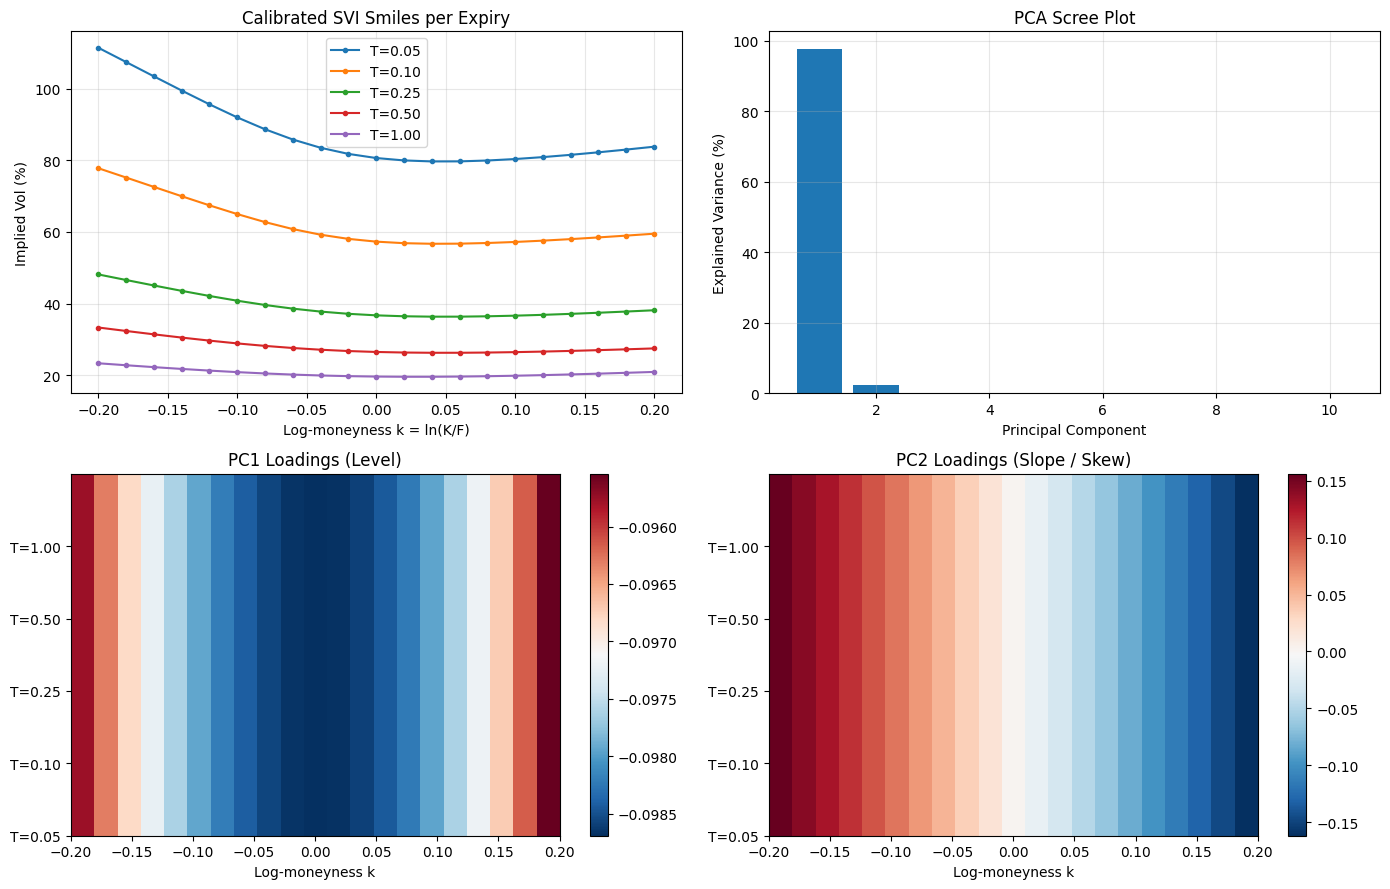


✅ SVI calibration + PCA pipeline complete.
   Saved plot: svi_pca_output.png


In [5]:
"""
SVI Volatility Surface Calibration + PCA Factor Analysis
========================================================
1. Generate a synthetic but realistic option chain (skew + smile).
2. Invert IV for each strike.
3. Calibrate SVI per expiry.
4. Build the surface across expiries.
5. Run PCA on surface changes → Level / Slope / Curvature.
"""

import numpy as np
import pandas as pd
from scipy.optimize import minimize, differential_evolution
import matplotlib.pyplot as plt


# ------------------------------------------------------------------
# Step 1: Synthetic market data (with skew + smile)
# ------------------------------------------------------------------
def generate_market_chain(S=100.0, r=0.05, q=0.0,
                          expiries=(0.05, 0.10, 0.25, 0.50, 1.00),
                          moneyness_range=(0.85, 1.15), n_strikes=25,
                          base_vol=0.20, seed=42):
    """
    Generate synthetic option prices using a known 'true' SVI-like smile.
    """
    rng = np.random.default_rng(seed)
    strikes = np.linspace(moneyness_range[0] * S, moneyness_range[1] * S, n_strikes)
    chain = []

    for T in expiries:
        # True SVI parameters per expiry (skew decreases with maturity)
        a = 0.02 + 0.005 * np.sqrt(T)
        b = 0.10 + 0.05 * np.exp(-3 * T)
        rho = -0.70 + 0.20 * T
        m = -0.05
        sigma_svi = 0.10 + 0.05 * T

        for K in strikes:
            k = np.log(K / (S * np.exp((r - q) * T)))  # log-moneyness
            w = a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + sigma_svi ** 2))
            iv_true = np.sqrt(max(w, 1e-6) / T)

            # Add tiny noise
            iv_noisy = iv_true + rng.normal(0, 0.001)

            # Price it with BS
            params = OptionInputs(S, K, T, iv_noisy, r, q)
            option_type = "call" if K >= S else "put"
            price = black_scholes_price(params, option_type)

            chain.append({
                "T": T, "K": K, "k": k, "option_type": option_type,
                "price": price, "iv_true": iv_true, "iv_noisy": iv_noisy,
            })

    return pd.DataFrame(chain), S, r, q


# ------------------------------------------------------------------
# Step 2: Raw SVI model & calibration
# ------------------------------------------------------------------
def svi_total_variance(k, a, b, rho, m, sigma):
    """Raw SVI: w(k) = a + b*(rho*(k-m) + sqrt((k-m)^2 + sigma^2))"""
    return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + sigma ** 2))


def svi_iv(k, T, params):
    a, b, rho, m, sigma = params
    w = svi_total_variance(k, a, b, rho, m, sigma)
    return np.sqrt(np.maximum(w, 1e-8) / T)


def svi_objective(params, k, T, iv_market, weights=None):
    a, b, rho, m, sigma = params
    if b < 0 or abs(rho) >= 1 or sigma <= 0:
        return 1e10
    iv_model = svi_iv(k, T, params)
    resid = iv_model - iv_market
    if weights is None:
        weights = np.ones_like(resid)
    return np.sum(weights * resid ** 2)


def calibrate_svi(k, T, iv_market):
    """
    Calibrate SVI with:
    - Differential evolution for global init (avoids local minima)
    - SLSQP for refined constrained fit
    """
    # Global search
    bounds = [(1e-6, 0.5), (1e-6, 1.0), (-0.999, 0.999),
              (-0.5, 0.5), (1e-4, 1.0)]
    result = differential_evolution(
        svi_objective, bounds, args=(k, T, iv_market),
        seed=42, maxiter=200, tol=1e-8, polish=True
    )
    x0 = result.x

    # Local refinement with no-arbitrage constraints
    # Butterfly arbitrage-free condition (Gatheral-Jacquier simplified):
    #   b * (1 + |rho|) <= 4 / T    (necessary condition)
    constraints = [
        {"type": "ineq", "fun": lambda p: 4.0 / T - p[1] * (1 + abs(p[2]))},
        {"type": "ineq", "fun": lambda p: p[1]},                 # b >= 0
        {"type": "ineq", "fun": lambda p: 1 - abs(p[2])},        # |rho| < 1
        {"type": "ineq", "fun": lambda p: p[4]},                 # sigma > 0
    ]
    bounds_slsqp = [(None, None), (0, 2), (-0.999, 0.999),
                    (-2, 2), (1e-6, 2)]

    result2 = minimize(
        svi_objective, x0, args=(k, T, iv_market),
        method="SLSQP", bounds=bounds_slsqp, constraints=constraints,
        options={"maxiter": 500, "ftol": 1e-12}
    )
    return result2.x, result2.fun


# ------------------------------------------------------------------
# Step 3: Run the full pipeline
# ------------------------------------------------------------------
print("=" * 60)
print("STEP 1: Generate synthetic market chain")
print("=" * 60)
chain, S, r, q = generate_market_chain()
print(f"Generated {len(chain)} option quotes across "
      f"{chain['T'].nunique()} expiries.")

print("\n" + "=" * 60)
print("STEP 2: Invert implied vol from prices")
print("=" * 60)
chain["iv_market"] = [
    implied_vol(row.price, S, row.K, row.T, r, row.option_type, q)
    for row in chain.itertuples()
]
print(f"IV inversion done. NaN count: {chain['iv_market'].isna().sum()}")

print("\n" + "=" * 60)
print("STEP 3: Calibrate SVI per expiry")
print("=" * 60)
svi_params_by_T = {}
for T, group in chain.groupby("T"):
    k = group["k"].values
    iv = group["iv_market"].values
    mask = ~np.isnan(iv)
    k, iv = k[mask], iv[mask]

    params, rmse = calibrate_svi(k, T, iv)
    svi_params_by_T[T] = params
    print(f"T = {T:.3f}y | SVI params (a,b,rho,m,sigma) = "
          f"({params[0]:.4f}, {params[1]:.4f}, {params[2]:.4f}, "
          f"{params[3]:.4f}, {params[4]:.4f}) | RMSE = {np.sqrt(rmse):.6f}")


# ------------------------------------------------------------------
# Step 4: Build the IV surface grid & PCA
# ------------------------------------------------------------------
print("\n" + "=" * 60)
print("STEP 4: Build IV surface grid for PCA")
print("=" * 60)

expiries_sorted = sorted(svi_params_by_T.keys())
k_grid = np.linspace(-0.20, 0.20, 21)

surface = np.zeros((len(expiries_sorted), len(k_grid)))
for i, T in enumerate(expiries_sorted):
    surface[i, :] = svi_iv(k_grid, T, svi_params_by_T[T])

surface_df = pd.DataFrame(
    surface * 100,
    index=[f"T={T:.2f}" for T in expiries_sorted],
    columns=[f"k={k:.2f}" for k in k_grid],
)
print("Surface grid (IV in %):")
print(surface_df.round(2))

# PCA on surface *changes* (simulate day-over-day by small perturbations)
print("\n" + "=" * 60)
print("STEP 5: PCA on surface changes (Level / Slope / Curvature)")
print("=" * 60)

rng = np.random.default_rng(0)
n_days = 200
# Simulate daily shocks: 3 latent factors driving surface changes
level_shock = rng.normal(0, 0.01, n_days)
slope_shock = rng.normal(0, 0.005, n_days)
curve_shock = rng.normal(0, 0.003, n_days)

surface_changes = np.zeros((n_days, len(expiries_sorted) * len(k_grid)))
col = 0
for i, T in enumerate(expiries_sorted):
    for j, k in enumerate(k_grid):
        level_load = 1.0
        slope_load = (j - len(k_grid) / 2) / len(k_grid)
        curve_load = ((j - len(k_grid) / 2) / len(k_grid)) ** 2
        surface_changes[:, col] = (level_shock * level_load
                                   + slope_shock * slope_load
                                   + curve_shock * curve_load)
        col += 1

# Standardize
X = surface_changes - surface_changes.mean(axis=0)
X = X / (X.std(axis=0) + 1e-12)

# SVD-based PCA
U, s, Vt = np.linalg.svd(X, full_matrices=False)
explained = (s ** 2) / np.sum(s ** 2)

print(f"Explained variance by PC1: {explained[0]*100:.2f}%")
print(f"Explained variance by PC2: {explained[1]*100:.2f}%")
print(f"Explained variance by PC3: {explained[2]*100:.2f}%")
print(f"First 3 PCs explain       : {explained[:3].sum()*100:.2f}%")

# ------------------------------------------------------------------
# Step 6: Plot
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Plot 1: IV smiles per expiry
ax = axes[0, 0]
for T in expiries_sorted:
    ax.plot(k_grid, surface[expiries_sorted.index(T), :] * 100,
            marker="o", markersize=3, label=f"T={T:.2f}")
ax.set_xlabel("Log-moneyness k = ln(K/F)")
ax.set_ylabel("Implied Vol (%)")
ax.set_title("Calibrated SVI Smiles per Expiry")
ax.legend()
ax.grid(alpha=0.3)

# Plot 2: PCA explained variance
ax = axes[0, 1]
ax.bar(range(1, 11), explained[:10] * 100)
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance (%)")
ax.set_title("PCA Scree Plot")
ax.grid(alpha=0.3)

# Plot 3: PC1 (Level)
ax = axes[1, 0]
pc1 = Vt[0, :].reshape(len(expiries_sorted), len(k_grid))
im = ax.imshow(pc1, aspect="auto", cmap="RdBu_r",
               extent=[k_grid[0], k_grid[-1], 0, len(expiries_sorted)])
ax.set_yticks(range(len(expiries_sorted)))
ax.set_yticklabels([f"T={T:.2f}" for T in expiries_sorted])
ax.set_xlabel("Log-moneyness k")
ax.set_title("PC1 Loadings (Level)")
plt.colorbar(im, ax=ax)

# Plot 4: PC2 (Slope)
ax = axes[1, 1]
pc2 = Vt[1, :].reshape(len(expiries_sorted), len(k_grid))
im = ax.imshow(pc2, aspect="auto", cmap="RdBu_r",
               extent=[k_grid[0], k_grid[-1], 0, len(expiries_sorted)])
ax.set_yticks(range(len(expiries_sorted)))
ax.set_yticklabels([f"T={T:.2f}" for T in expiries_sorted])
ax.set_xlabel("Log-moneyness k")
ax.set_title("PC2 Loadings (Slope / Skew)")
plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig("svi_pca_output.png", dpi=120, bbox_inches="tight")
plt.show()

print("\n✅ SVI calibration + PCA pipeline complete.")
print("   Saved plot: svi_pca_output.png")